# Google Quick, Draw! - CNN Architecture Comparison

**Why this notebook exists.** It compares *several clearly labelled CNN architectures*, each with its main settings, accuracy, macro precision/recall/F1, and an explanation of what changed from the previous architecture, whether it improved, whether training became slower, whether overfitting got better or worse, and why. Notebook 05 tuned hyperparameters one at a time; this notebook compares genuinely different **architectures** under one identical training protocol.

**Protocol (same for every architecture).** Adam, learning rate 0.001, batch size 64, dropout 0.3 before the output layer, dense layer of 128 units, early stopping on validation loss (patience 3, restore best weights, max 30 epochs), seed 42. Training data for fitting, **validation data for scoring and selection**. The test set is not loaded.

**Important.** The model that went through the single final test evaluation (notebook 06) is the tuned CNN saved by notebook 05. Nothing here changes that. If another architecture scores higher on validation, discuss it in the report; do not re-run the test set without agreeing it with the team.



## 1. Setup

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
from sklearn.preprocessing import label_binarize

SEED = 42
keras.utils.set_random_seed(SEED)

root = Path("..")
data_path   = root / "data" / "quickdraw" / "quickdraw_8class_processed.npz"
results_dir = root / "results"
figures_dir = root / "figures"
results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Load training and validation data

In [2]:
data = np.load(data_path, allow_pickle=True)
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]          # test arrays are deliberately not loaded
categories = [str(c) for c in data["categories"]]
n_classes = len(categories)
y_val_bin = label_binarize(y_val, classes=list(range(n_classes)))
print(X_train.shape, X_val.shape)

(19200, 28, 28, 1) (2400, 28, 28, 1)


## 3. The six architectures

Each architecture is a list of convolutional blocks (filters, kernel size, number of convolutions per block). Every block ends with 2x2 max pooling. The head is Flatten, Dense(128, ReLU), Dropout(0.3), Dense(8, softmax). `compare_to` says which earlier architecture each one is compared against in the difference table.

In [3]:
ARCHITECTURES = [
    {"name": "Arch 1: 1 conv block",            "blocks": [(32, 3, 1)],                       "batchnorm": False, "compare_to": None,
     "change": "reference: a single conv block (32 filters)"},
    {"name": "Arch 2: 2 conv blocks (v1)",      "blocks": [(32, 3, 1), (64, 3, 1)],           "batchnorm": False, "compare_to": 0,
     "change": "adds a second conv block (64 filters)"},
    {"name": "Arch 3: 3 conv blocks (tuned)",   "blocks": [(32, 3, 1), (64, 3, 1), (128, 3, 1)], "batchnorm": False, "compare_to": 1,
     "change": "adds a third conv block (128 filters)"},
    {"name": "Arch 4: 3 blocks, 5x5 kernels",   "blocks": [(32, 5, 1), (64, 5, 1), (128, 5, 1)], "batchnorm": False, "compare_to": 2,
     "change": "3x3 kernels replaced by 5x5 kernels"},
    {"name": "Arch 5: 3 blocks + BatchNorm",    "blocks": [(32, 3, 1), (64, 3, 1), (128, 3, 1)], "batchnorm": True,  "compare_to": 2,
     "change": "BatchNormalization after every conv"},
    {"name": "Arch 6: 3 blocks, 2 convs each",  "blocks": [(32, 3, 2), (64, 3, 2), (128, 3, 2)], "batchnorm": False, "compare_to": 2,
     "change": "two stacked convs in every block"},
]

def build_arch(spec, dense_units=128, dropout=0.3, learning_rate=1e-3):
    model_layers = [keras.Input(shape=(28, 28, 1))]
    for filters, kernel, n_convs in spec["blocks"]:
        for _ in range(n_convs):
            if spec["batchnorm"]:
                model_layers += [layers.Conv2D(filters, (kernel, kernel), padding="same", use_bias=False),
                                 layers.BatchNormalization(), layers.Activation("relu")]
            else:
                model_layers += [layers.Conv2D(filters, (kernel, kernel), padding="same", activation="relu")]
        model_layers += [layers.MaxPooling2D((2, 2))]
    model_layers += [layers.Flatten(), layers.Dense(dense_units, activation="relu"),
                     layers.Dropout(dropout), layers.Dense(n_classes, activation="softmax")]
    model = keras.Sequential(model_layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def describe(spec):
    blocks = ", ".join(f"{f}f {k}x{k}" + (f" x{n}" if n > 1 else "") for f, k, n in spec["blocks"])
    return f"{blocks}{' + BatchNorm' if spec['batchnorm'] else ''}; dense 128; dropout 0.3; Adam 1e-3; batch 64"

for a in ARCHITECTURES:
    print(f"{a['name']:34s} {describe(a)}")

Arch 1: 1 conv block               32f 3x3; dense 128; dropout 0.3; Adam 1e-3; batch 64
Arch 2: 2 conv blocks (v1)         32f 3x3, 64f 3x3; dense 128; dropout 0.3; Adam 1e-3; batch 64
Arch 3: 3 conv blocks (tuned)      32f 3x3, 64f 3x3, 128f 3x3; dense 128; dropout 0.3; Adam 1e-3; batch 64
Arch 4: 3 blocks, 5x5 kernels      32f 5x5, 64f 5x5, 128f 5x5; dense 128; dropout 0.3; Adam 1e-3; batch 64
Arch 5: 3 blocks + BatchNorm       32f 3x3, 64f 3x3, 128f 3x3 + BatchNorm; dense 128; dropout 0.3; Adam 1e-3; batch 64
Arch 6: 3 blocks, 2 convs each     32f 3x3 x2, 64f 3x3 x2, 128f 3x3 x2; dense 128; dropout 0.3; Adam 1e-3; batch 64


## 4. Train every architecture with the same protocol (validation only)

In [4]:
results, histories = [], {}
for spec in ARCHITECTURES:
    keras.utils.set_random_seed(SEED)                       # same seed => fair comparison
    model = build_arch(spec)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    start = time.perf_counter()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30,
                     batch_size=64, callbacks=[stop], verbose=0)
    seconds = time.perf_counter() - start
    probs = model.predict(X_val, verbose=0)
    pred = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_val, pred, average="macro", zero_division=0)
    h = hist.history
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    train_acc = h["accuracy"][best_epoch - 1]
    val_acc = accuracy_score(y_val, pred)
    results.append({
        "Architecture": spec["name"], "Main settings": describe(spec), "Params": model.count_params(),
        "Epochs run": len(h["loss"]), "Best epoch": best_epoch,
        "Train acc": train_acc, "Val acc": val_acc, "Macro precision": p, "Macro recall": r, "Macro F1": f1,
        "Macro ROC-AUC": roc_auc_score(y_val_bin, probs, average="macro"),
        "Train-val gap": train_acc - val_acc, "Train time (s)": seconds,
        "Seconds / epoch": seconds / len(h["loss"]),
    })
    histories[spec["name"]] = h
    print(f"{spec['name']:34s} val acc {val_acc:.4f} | macro F1 {f1:.4f} | params {model.count_params():,} | {seconds:.0f}s")
    keras.backend.clear_session()

arch_table = pd.DataFrame(results)
arch_table.round(4).to_csv(results_dir / "quickdraw_cnn_architectures.csv", index=False)

Arch 1: 1 conv block               val acc 0.9383 | macro F1 0.9383 | params 804,296 | 20s

Arch 2: 2 conv blocks (v1)         val acc 0.9479 | macro F1 0.9479 | params 421,384 | 26s
Arch 3: 3 conv blocks (tuned)      val acc 0.9554 | macro F1 0.9556 | params 241,288 | 29s
Arch 4: 3 blocks, 5x5 kernels      val acc 0.9533 | macro F1 0.9534 | params 405,640 | 55s
Arch 5: 3 blocks + BatchNorm       val acc 0.9500 | macro F1 0.9500 | params 241,960 | 81s
Arch 6: 3 blocks, 2 convs each     val acc 0.9529 | macro F1 0.9533 | params 435,048 | 61s


## 5. Architecture table (validation set; best macro F1 highlighted)

In [5]:
show = arch_table.round(4)
try:
    display(show.style.highlight_max(subset=["Macro F1"], props="font-weight: bold; background-color: #d6f5d6"))
except Exception:
    display(show)

,Architecture,Main settings,Params,Epochs run,Best epoch,Train acc,Val acc,Macro precision,Macro recall,Macro F1,Macro ROC-AUC,Train-val gap,Train time (s),Seconds / epoch
0,Arch 1: 1 conv block,32f 3x3; dense 128; dropout 0.3; Adam 1e-3; batch 64,804296,8,5,0.951500,0.938300,0.938500,0.938300,0.938300,0.994800,0.013200,20.033500,2.504200
1,Arch 2: 2 conv blocks (v1),"32f 3x3, 64f 3x3; dense 128; dropout 0.3; Adam 1e-3; batch 64",421384,8,5,0.953900,0.947900,0.948000,0.947900,0.947900,0.997200,0.005900,25.643700,3.205500
2,Arch 3: 3 conv blocks (tuned),"32f 3x3, 64f 3x3, 128f 3x3; dense 128; dropout 0.3; Adam 1e-3; batch 64",241288,8,5,0.962600,0.955400,0.956000,0.955400,0.955600,0.997800,0.007200,28.748900,3.593600
3,"Arch 4: 3 blocks, 5x5 kernels","32f 5x5, 64f 5x5, 128f 5x5; dense 128; dropout 0.3; Adam 1e-3; batch 64",405640,8,5,0.972200,0.953300,0.953900,0.953300,0.953400,0.997800,0.018900,54.502600,6.812800
4,Arch 5: 3 blocks + BatchNorm,"32f 3x3, 64f 3x3, 128f 3x3 + BatchNorm; dense 128; dropout 0.3; Adam 1e-3; batch 64",241960,11,8,0.976500,0.950000,0.952000,0.950000,0.950000,0.998100,0.026500,81.396700,7.399700
5,"Arch 6: 3 blocks, 2 convs each","32f 3x3 x2, 64f 3x3 x2, 128f 3x3 x2; dense 128; dropout 0.3; Adam 1e-3; batch 64",435048,7,4,0.955700,0.952900,0.954300,0.952900,0.953300,0.997600,0.002800,60.764700,8.680700


## 6. What changed from the reference architecture (computed from the table)

Differences are computed automatically against the architecture named in the `Compared with` column. A positive F1 difference means the architecture scored higher. **Overfitting** is judged from the train-validation accuracy gap at the best epoch (a larger gap means more overfitting). Differences smaller than about 0.005 in macro F1 are within the run-to-run noise seen between machines, so treat them as "no clear change".

In [6]:
def difference_table(table, specs, noise=0.005):
    rows = []
    for i, spec in enumerate(specs):
        if spec["compare_to"] is None:
            continue
        a, b = table.iloc[i], table.iloc[spec["compare_to"]]
        d_f1 = a["Macro F1"] - b["Macro F1"]
        d_time = a["Train time (s)"] - b["Train time (s)"]
        d_gap = a["Train-val gap"] - b["Train-val gap"]
        rows.append({
            "Architecture": a["Architecture"], "Compared with": b["Architecture"], "What changed": spec["change"],
            "Delta macro F1": d_f1,
            "Performance": "no clear change" if abs(d_f1) < noise else ("improved" if d_f1 > 0 else "worse"),
            "Delta train time (s)": d_time, "Training": "slower" if d_time > 0 else "faster",
            "Delta params": int(a["Params"] - b["Params"]),
            "Delta train-val gap": d_gap,
            "Overfitting": "about the same" if abs(d_gap) < 0.005 else ("worse" if d_gap > 0 else "better"),
        })
    return pd.DataFrame(rows)

diff_table = difference_table(arch_table, ARCHITECTURES)
diff_table.round(4).to_csv(results_dir / "quickdraw_cnn_architecture_differences.csv", index=False)
display(diff_table.round(4))

,Architecture,Compared with,What changed,Delta macro F1,Performance,Delta train time (s),Training,Delta params,Delta train-val gap,Overfitting
0,Arch 2: 2 conv blocks (v1),Arch 1: 1 conv block,adds a second conv block (64 filters),0.0096,improved,5.6102,slower,-382912,-0.0072,better
1,Arch 3: 3 conv blocks (tuned),Arch 2: 2 conv blocks (v1),adds a third conv block (128 filters),0.0077,improved,3.1052,slower,-180096,0.0013,about the same
2,"Arch 4: 3 blocks, 5x5 kernels",Arch 3: 3 conv blocks (tuned),3x3 kernels replaced by 5x5 kernels,-0.0022,no clear change,25.7537,slower,164352,0.0117,worse
3,Arch 5: 3 blocks + BatchNorm,Arch 3: 3 conv blocks (tuned),BatchNormalization after every conv,-0.0056,worse,52.6479,slower,672,0.0193,worse
4,"Arch 6: 3 blocks, 2 convs each",Arch 3: 3 conv blocks (tuned),two stacked convs in every block,-0.0023,no clear change,32.0158,slower,193760,-0.0044,about the same


## 7. Why did each change behave this way?

Arch 2 v 1 - The second conv block allows the model to combine simple strokes into larger parts like wheels or wings. The model overfitted less as well, with Macro F1 increasing by 0.0096 and the train-val gap decreasing by 0.0072. This is because the second pooling layer halves the feature maps again before the dense layer where most parameters are by 382,912 parameters. Training was 5.6s adrift

Arch 3 v 2 - A third block learns even larger shapes, such as whole outlines. Macro F1 improved by 0.0077 and overfitting was roughly the same. The maps get reduced from 7x7 to 3x3 thanks to the added pooling . This means far fewer values go into the dense layer , which has 180,096 fewer parameters . It only cost an additional 3.1 s.

Arch 4 vs 3 - A 5x5 kernel sees a bigger area at once than a 3x3 kernel . But stacked 3x3 layers already cover that area so there was no clear change in F1 (-0.0022). It added 164,352 parameters, cost an additional 25.8 s, and increased the train-val gap by 0.0117. So it overfit more for no gain.

Arch 5 vs 3 - BatchNorm normalises the outputs of each conv layer during training, which usually leads to more stable training. But our model trained well without that already. Macro F1 dropped by 0.0056 (just above noise level), the gap train-val increased by 0.0193 and training took 52.6 s longer. So that didn’t help this little model.

Arch 6 vs 3 - Each block has more layers to learn detail before pooling with two stacked convs per block. The F1 did not change significantly (-0.0023) and the overfitting was similar, but it added 193,760 parameters and was 32 s longer. Arch 3 is still the best, the extra time was not worth it.

## 8. Training vs validation curves for every architecture

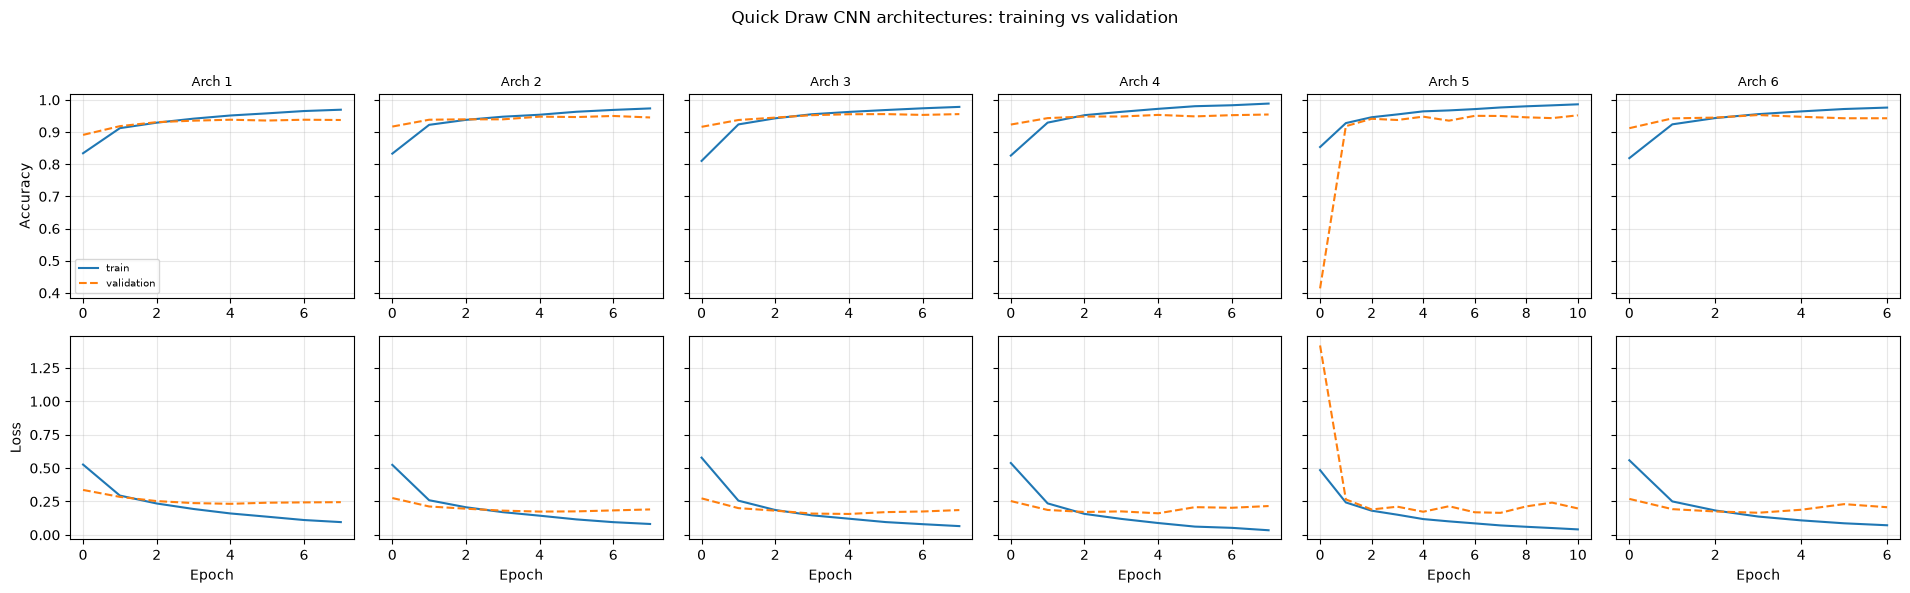

In [7]:
fig, axes = plt.subplots(2, len(ARCHITECTURES), figsize=(3.2 * len(ARCHITECTURES), 6), sharey="row")
for j, (name, h) in enumerate(histories.items()):
    axes[0, j].plot(h["accuracy"], label="train"); axes[0, j].plot(h["val_accuracy"], "--", label="validation")
    axes[1, j].plot(h["loss"], label="train");     axes[1, j].plot(h["val_loss"], "--", label="validation")
    axes[0, j].set_title(name.split(":")[0], fontsize=9)
    axes[1, j].set_xlabel("Epoch")
    for i in (0, 1):
        axes[i, j].grid(alpha=0.3)
axes[0, 0].set_ylabel("Accuracy"); axes[1, 0].set_ylabel("Loss"); axes[0, 0].legend(fontsize=7)
fig.suptitle("Quick Draw CNN architectures: training vs validation")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(figures_dir / "quickdraw_cnn_architectures_curves.png", dpi=150)
plt.show()

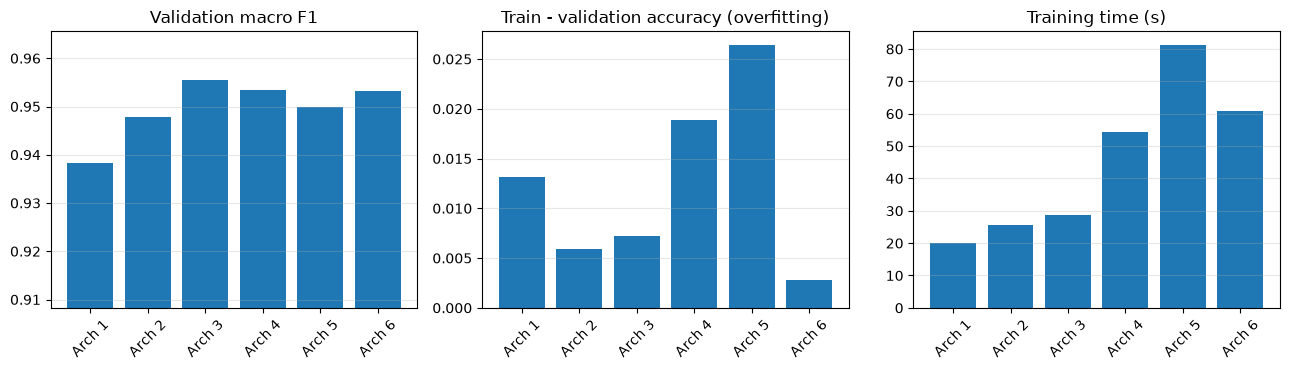

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
short = [n.split(":")[0] for n in arch_table["Architecture"]]
axes[0].bar(short, arch_table["Macro F1"]);        axes[0].set_title("Validation macro F1")
axes[1].bar(short, arch_table["Train-val gap"]);   axes[1].set_title("Train - validation accuracy (overfitting)")
axes[2].bar(short, arch_table["Train time (s)"]);  axes[2].set_title("Training time (s)")
axes[0].set_ylim(max(0.0, arch_table["Macro F1"].min() - 0.03), min(1.0, arch_table["Macro F1"].max() + 0.01))
for ax in axes:
    ax.tick_params(axis="x", rotation=45); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_architectures_summary.png", dpi=150)
plt.show()

## 9. Results

1. Arch 3 (three 3x3 conv blocks) is the best on validation with macro F1 of 0.9556. It has a small lead over Arch 4 (0.9534) and Arch 6 (0.9533) of about 0.002, which is below the noise level of 0.005, so it is not significantly better than them. Arch 1 (0.9383), Arch 2 (0.9479) and slightly above the noise Arch 5 (0.9500) is clearly worse.

2. Yes. Going from 1 to 3 blocks increased F1 and only added about 9 seconds (20 s to 29 s). The extra changes afterward take a lot longer without improving F1 i.e Arch 4 took 55 s, Arch 6 took 61 s and Arch 5 took 81 s. Arch 4 and Arch 5 also overfitted more (train-val gaps of 0.0189 and 0.0265 versus 0.0072 for Arch 3). Arch 6 had the smallest gap (0.0028) but was twice as long as Arch 3 with no improvement. Arch 3 has the best balance: the highest F1, the least parameters (241,288) a short training time and a small gap.

3. Arch 3 is the same model as the tuned CNN from notebook 05 and got the exact same validation results here (0.9554 accuracy, 0.9556 macro F1), so the result is reproducible. None of the other architectures clearly outperform it, which supports our choice of using it for the one-off test evaluation in notebook 06 (0.9400 accuracy and macro F1). It also means we don’t have to re-test a different model.

4. We would expect a deeper architecture to help most with airplane, cat and fish and also guitar. These classes are similar in overall shape, with a body and little bits sticking out, so the difference is in how those bits are arranged in the whole picture (ears on a head, wings across a body, fins and tail). Deeper layers see more of the image, so they can learn these whole-shape patterns. However, after three pooling layers, the 28x28 image is already reduced to 3x3 and the results show little gain of going deeper. More data or higher resolution images will probably help these classes more than additional layers.